In [1]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

np.set_printoptions(precision=4, suppress=True)

---
## 1.1 See the four subspaces in 3-D

**Task.** Take a random $3\times 3$ matrix of rank 2. Compute bases of its row space, null space, column space and left null space with the SVD. Plot each pair (row space + null space, column space + left null space) in an interactive 3-D figure.

### Prediction

For a $3\times3$ matrix of rank 2, I expect:

- $\dim \mathrm{RS}(A) = 2$, $\dim \mathrm{NS}(A) = 1$ → geometrically: a 'plane' and a 'line'
- $\dim \mathrm{CS}(A) = 2$, $\dim \mathrm{LNS}(A) = 1$ → geometrically: a 'plane' and a 'line'
- The angle between the row space and the null space will be: 90

### Building a matrix with a chosen rank

A product $A = XY$ with $X\in\mathbb{R}^{m\times r}$, $Y\in\mathbb{R}^{r\times n}$ has rank at most $r$ (every column of $A$ is a combination of the $r$ columns of $X$).

For readability, $X$ and $Y$ get small integer entries in $\{-3, \dots, 3\}$, so $A$ is an integer matrix. With integers the rank can occasionally come out *lower* than $r$ by bad luck (e.g. two columns of $X$ happen to be parallel), so we draw again until it is exactly $r$.

In [2]:
def random_matrix_of_rank(m, n, r, seed=0, low=-3, high=3):
    rng = np.random.default_rng(seed)
    while True:
        X = rng.integers(low, high + 1, size=(m, r))
        Y = rng.integers(low, high + 1, size=(r, n))
        A = X @ Y
        if np.linalg.matrix_rank(A) == r:
            return A.astype(float)

A = random_matrix_of_rank(3, 3, 2, seed=0)
print(A)
print("rank:", np.linalg.matrix_rank(A))

[[-4. -5. -1.]
 [-4. -2. -6.]
 [-3.  0. -7.]]
rank: 2


### The four subspaces from the SVD

With the full SVD $A = U\Sigma V^\top$ ($U \in \mathbb{R}^{m\times m}$, $V\in\mathbb{R}^{n\times n}$ orthogonal) and $r$ = number of non-zero singular values:

| subspace | lives in | basis | dimension |
|---|---|---|---|
| row space $\mathrm{RS}(A)$ | $\mathbb{R}^n$ | first $r$ columns of $V$ | $r$ |
| null space $\mathrm{NS}(A)$ | $\mathbb{R}^n$ | last $n-r$ columns of $V$ | $n-r$ |
| column space $\mathrm{CS}(A)$ | $\mathbb{R}^m$ | first $r$ columns of $U$ | $r$ |
| left null space $\mathrm{LNS}(A)$ | $\mathbb{R}^m$ | last $m-r$ columns of $U$ | $m-r$ |

"Non-zero" numerically means above a tolerance; we use the same one as `np.linalg.matrix_rank`.

In [3]:
def four_subspaces(A):
    m, n = A.shape
    U, s, Vt = np.linalg.svd(A)              # full SVD: U (m×m), Vt (n×n)
    tol = s.max() * max(m, n) * np.finfo(float).eps
    r = int(np.sum(s > tol))
    V = Vt.T
    return {
        "U": U, "s": s, "V": V, "r": r,
        "RS":  V[:, :r],    # in R^n
        "NS":  V[:, r:],    # in R^n
        "CS":  U[:, :r],    # in R^m
        "LNS": U[:, r:],    # in R^m
    }

S = four_subspaces(A)
print("singular values:", S["s"], " -> rank", S["r"])
for name in ["RS", "NS", "CS", "LNS"]:
    print(f"\n{name} basis (columns), dim = {S[name].shape[1]}:\n{S[name]}")

singular values: [11.2457  5.4345  0.    ]  -> rank 2

RS basis (columns), dim = 2:
[[ 0.546  -0.3339]
 [ 0.2937 -0.7826]
 [ 0.7846  0.5254]]

NS basis (columns), dim = 1:
[[ 0.7683]
 [-0.5488]
 [-0.3293]]

CS basis (columns), dim = 2:
[[-0.3946  0.8691]
 [-0.6651 -0.0462]
 [-0.634  -0.4924]]

LNS basis (columns), dim = 1:
[[ 0.2981]
 [-0.7454]
 [ 0.5963]]


### Verify numerically (rule 3)

Each claim gets a one-line `np.allclose` check.

In [4]:
def verify(A, S):
    m, n = A.shape
    U, s, V, r = S["U"], S["s"], S["V"], S["r"]
    Sigma = np.zeros((m, n)); np.fill_diagonal(Sigma, s)
    checks = {
        "A = U Σ Vᵀ":                       np.allclose(A, U @ Sigma @ V.T),
        "A · NS = 0      (NS ⊂ ker A)":     np.allclose(A @ S["NS"], 0),
        "Aᵀ · LNS = 0    (LNS ⊂ ker Aᵀ)":   np.allclose(A.T @ S["LNS"], 0),
        "RSᵀ · NS = 0    (RS ⟂ NS)":        np.allclose(S["RS"].T @ S["NS"], 0),
        "CSᵀ · LNS = 0   (CS ⟂ LNS)":       np.allclose(S["CS"].T @ S["LNS"], 0),
        "rows of A lie in RS":              np.allclose(S["RS"] @ S["RS"].T @ A.T, A.T),
        "columns of A lie in CS":           np.allclose(S["CS"] @ S["CS"].T @ A, A),
        f"dim RS + dim NS = n = {n}":       S["RS"].shape[1] + S["NS"].shape[1] == n,
        f"dim CS + dim LNS = m = {m}":      S["CS"].shape[1] + S["LNS"].shape[1] == m,
    }
    for k, v in checks.items():
        print(f"{'✓' if v else '✗'}  {k}")

verify(A, S)

✓  A = U Σ Vᵀ
✓  A · NS = 0      (NS ⊂ ker A)
✓  Aᵀ · LNS = 0    (LNS ⊂ ker Aᵀ)
✓  RSᵀ · NS = 0    (RS ⟂ NS)
✓  CSᵀ · LNS = 0   (CS ⟂ LNS)
✓  rows of A lie in RS
✓  columns of A lie in CS
✓  dim RS + dim NS = n = 3
✓  dim CS + dim LNS = m = 3


### Plotting helpers

A subspace of $\mathbb{R}^3$ is drawn according to its dimension:

- dim 0 → just the origin (a dot)
- dim 1 → a line through the origin
- dim 2 → a plane through the origin
- dim 3 → all of $\mathbb{R}^3$ (a faint cube)

Basis vectors are drawn as arrows. On top we also plot the **rows** of $A$ (left panel) and the **columns** of $A$ (right panel) as markers, to see that they really lie in RS and CS.

In [5]:
L = 1.5  # half-size of the drawn region

def arrow(v, color, name, showlegend=False):
    return [
        go.Scatter3d(x=[0, v[0]], y=[0, v[1]], z=[0, v[2]], mode="lines",
                     line=dict(color=color, width=6), name=name,
                     legendgroup=name, showlegend=showlegend),
        go.Cone(x=[v[0]], y=[v[1]], z=[v[2]], u=[v[0]], v=[v[1]], w=[v[2]],
                sizemode="absolute", sizeref=0.15, anchor="tip",
                colorscale=[[0, color], [1, color]], showscale=False,
                legendgroup=name, showlegend=False, hoverinfo="skip"),
    ]

def subspace_traces(B, color, name):
    # Traces drawing span(columns of B) in R^3; B has orthonormal columns.
    d = B.shape[1]
    t = np.linspace(-L, L, 2)
    if d == 0:
        traces = [go.Scatter3d(x=[0], y=[0], z=[0], mode="markers",
                               marker=dict(size=8, color=color),
                               name=f"{name} = {{0}}", legendgroup=name)]
    elif d == 1:
        p = np.outer(B[:, 0], t)
        traces = [go.Scatter3d(x=p[0], y=p[1], z=p[2], mode="lines",
                               line=dict(color=color, width=4, dash="dash"),
                               name=f"{name} (line)", legendgroup=name)]
    elif d == 2:
        s_, t_ = np.meshgrid(t, t)
        P = B[:, [0]] * s_.ravel() + B[:, [1]] * t_.ravel()
        traces = [go.Surface(x=P[0].reshape(2, 2), y=P[1].reshape(2, 2), z=P[2].reshape(2, 2),
                             colorscale=[[0, color], [1, color]], opacity=0.35,
                             showscale=False, name=f"{name} (plane)",
                             legendgroup=name, showlegend=True)]
    else:  # d == 3: the whole space
        c = np.array([[x, y, z] for x in (-L, L) for y in (-L, L) for z in (-L, L)])
        traces = [go.Mesh3d(x=c[:, 0], y=c[:, 1], z=c[:, 2], alphahull=0,
                            color=color, opacity=0.08, name=f"{name} = R³",
                            legendgroup=name, showlegend=True)]
    for i in range(d):
        traces += arrow(B[:, i], color, name)
    return traces

def points_trace(P, color, name):
    # P: 3 × k, each column a point
    return go.Scatter3d(x=P[0], y=P[1], z=P[2], mode="markers",
                        marker=dict(size=5, color=color, symbol="diamond",
                                    line=dict(color="black", width=1)),
                        name=name)

def plot_four_subspaces(A, title=""):
    S = four_subspaces(A)
    scale = L / np.abs(A).max()   # shrink rows/cols of A to fit the box
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                        subplot_titles=[f"Domain ℝⁿ: RS (dim {S['RS'].shape[1]}) ⟂ NS (dim {S['NS'].shape[1]})",
                                        f"Codomain ℝᵐ: CS (dim {S['CS'].shape[1]}) ⟂ LNS (dim {S['LNS'].shape[1]})"])
    for tr in subspace_traces(S["RS"], "royalblue", "RS") + subspace_traces(S["NS"], "crimson", "NS"):
        fig.add_trace(tr, row=1, col=1)
    fig.add_trace(points_trace(scale * A.T, "royalblue", "rows of A (scaled)"), row=1, col=1)
    for tr in subspace_traces(S["CS"], "seagreen", "CS") + subspace_traces(S["LNS"], "darkorange", "LNS"):
        fig.add_trace(tr, row=1, col=2)
    fig.add_trace(points_trace(scale * A, "seagreen", "columns of A (scaled)"), row=1, col=2)
    axis = dict(range=[-L, L])
    scene = dict(xaxis=axis, yaxis=axis, zaxis=axis, aspectmode="cube")
    fig.update_layout(scene=scene, scene2=scene, height=550,
                      title=title or f"rank(A) = {S['r']}", legend=dict(itemsizing="constant"))
    fig.show()
    return S

In [6]:
S = plot_four_subspaces(A, "Random 3×3 matrix of rank 2")

- The arrows are an orthonormal basis that the SVD gives you directly: the first r columns of V for the row space and the first r columns of U for the column space. They have length 1 and meet at right angles.
- The diamonds (the rows and columns of A) also span those planes, but they are not orthogonal and not of length 1. They form an ordinary basis, or even a set with extras.

---
### Explore: change the rank to 1 and to 3

Before running: which subspaces do you expect to **grow**, **shrink** or **disappear** (become $\{0\}$)?

- Rank 1: RS and CS shrink into a line. NS and LNS grow to a plane
- Rank 3: Full rank matrix. The NS and LNS become {0} 

In [20]:
for r in [1, 3]:
    A_r = random_matrix_of_rank(3, 3, r, seed=1)
    print(f"===== rank {r} =====")
    S_r = plot_four_subspaces(A_r, f"Random 3×3 matrix of rank {r}")
    verify(A_r, S_r)
    print()

===== rank 1 =====


✓  A = U Σ Vᵀ
✓  A · NS = 0      (NS ⊂ ker A)
✓  Aᵀ · LNS = 0    (LNS ⊂ ker Aᵀ)
✓  RSᵀ · NS = 0    (RS ⟂ NS)
✓  CSᵀ · LNS = 0   (CS ⟂ LNS)
✓  rows of A lie in RS
✓  columns of A lie in CS
✓  dim RS + dim NS = n = 3
✓  dim CS + dim LNS = m = 3

===== rank 3 =====


✓  A = U Σ Vᵀ
✓  A · NS = 0      (NS ⊂ ker A)
✓  Aᵀ · LNS = 0    (LNS ⊂ ker Aᵀ)
✓  RSᵀ · NS = 0    (RS ⟂ NS)
✓  CSᵀ · LNS = 0   (CS ⟂ LNS)
✓  rows of A lie in RS
✓  columns of A lie in CS
✓  dim RS + dim NS = n = 3
✓  dim CS + dim LNS = m = 3



---
### Explain (hand-in — in your own words)

**1. Which subspaces grow, shrink or disappear as the rank goes 1 → 2 → 3?**

*Your answer.*

**2. Why is the null space always perpendicular to the row space?**
*(Hint: write out what $Ax = 0$ says row by row, and what that means for $x$ and every row $a_i^\top$ — and hence every combination of rows.)*

*Your answer.*

**3. Check $\dim \mathrm{RS}(A) + \dim \mathrm{NS}(A) = n$ and $\dim \mathrm{CS}(A) + \dim \mathrm{LNS}(A) = m$ for each case. Why must these hold?**
*(Hint: the columns of $V$ are an orthonormal basis of $\mathbb{R}^n$, split into the first $r$ and the last $n-r$.)*

*Your answer.*

---
## 1.2 Where does $A$ send a vector?

**Task.** For a rank-1 $2\times 2$ matrix, draw a grid of input vectors and their images $Ax$. Colour each input by its component along the null space.

### Prediction (written before running)

> $A$ sends a vector $v$ from the row space of $A$ to the column space of $A$.

Refined after discussion: **every** $x\in\mathbb{R}^n$ lands in the column space. Splitting $x = x_r + x_{ns}$, the null-space part is sent to $0$, so only the row-space part decides where $x$ goes. Expected picture: the whole input grid collapses onto one line (CS), and inputs that differ only in their NS component land on the **same** point.

In [10]:
import matplotlib.pyplot as plt

# A rank-1 2×2 matrix: A = u vᵀ  (columns are multiples of u, rows multiples of vᵀ)
u = np.array([1.0, 0.5])
v = np.array([1.0, 2.0])
A2 = np.outer(u, v)
print(A2)

S2 = four_subspaces(A2)
rs, ns = S2["RS"][:, 0], S2["NS"][:, 0]     # unit vectors in R^2
cs, lns = S2["CS"][:, 0], S2["LNS"][:, 0]
print("rank:", S2["r"])
print("RS  direction:", rs, "   NS  direction:", ns)
print("CS  direction:", cs, "   LNS direction:", lns)
verify(A2, S2)

[[1.  2. ]
 [0.5 1. ]]
rank: 1
RS  direction: [-0.4472 -0.8944]    NS  direction: [ 0.8944 -0.4472]
CS  direction: [-0.8944 -0.4472]    LNS direction: [-0.4472  0.8944]
✓  A = U Σ Vᵀ
✓  A · NS = 0      (NS ⊂ ker A)
✓  Aᵀ · LNS = 0    (LNS ⊂ ker Aᵀ)
✓  RSᵀ · NS = 0    (RS ⟂ NS)
✓  CSᵀ · LNS = 0   (CS ⟂ LNS)
✓  rows of A lie in RS
✓  columns of A lie in CS
✓  dim RS + dim NS = n = 2
✓  dim CS + dim LNS = m = 2


### Grid of inputs and their images

Each input $x$ gets two coordinates in the orthonormal basis $\{r, n\}$ (row space, null space):

$$x = \underbrace{(r^\top x)\,r}_{x_r} + \underbrace{(n^\top x)\,n}_{x_{ns}}$$

Top row: colour by the **null-space** component $n^\top x$ (what the task asks).
Bottom row: same points, coloured by the **row-space** component $r^\top x$, for comparison.

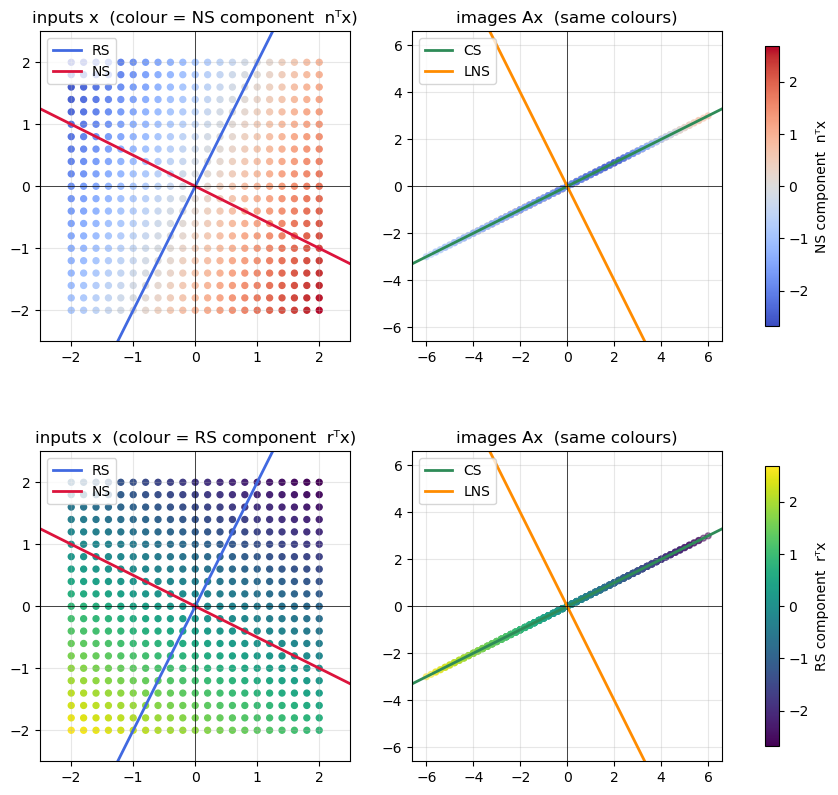

In [11]:
g = np.linspace(-2, 2, 21)
X = np.array(np.meshgrid(g, g)).reshape(2, -1)   # 2 × N grid of inputs
AX = A2 @ X                                      # 2 × N images
c_ns = ns @ X                                    # component along NS
c_rs = rs @ X                                    # component along RS

def draw_line(ax, d, color, label, L=10):
    ax.plot([-L * d[0], L * d[0]], [-L * d[1], L * d[1]], color=color, lw=2, label=label)

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row, (c, cname, cmap) in enumerate([(c_ns, "NS component  nᵀx", "coolwarm"),
                                        (c_rs, "RS component  rᵀx", "viridis")]):
    ax_in, ax_out = axes[row]
    sc = ax_in.scatter(*X, c=c, cmap=cmap, s=18)
    draw_line(ax_in, rs, "royalblue", "RS")
    draw_line(ax_in, ns, "crimson", "NS")
    ax_in.set_title(f"inputs x  (colour = {cname})")
    ax_out.scatter(*AX, c=c, cmap=cmap, s=18, alpha=0.5)
    draw_line(ax_out, cs, "seagreen", "CS")
    draw_line(ax_out, lns, "darkorange", "LNS")
    ax_out.set_title(f"images Ax  (same colours)")
    fig.colorbar(sc, ax=[ax_in, ax_out], shrink=0.8, label=cname)
for ax in axes[:, 0]:
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
for ax in axes[:, 1]:
    lim = np.abs(AX).max() * 1.1
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
for ax in axes.ravel():
    ax.set_aspect("equal"); ax.axhline(0, c="k", lw=0.5); ax.axvline(0, c="k", lw=0.5)
    ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.show()

**What to look for:**
- Top right: every colour of the NS scale is piled on top of each other at each image point, because the NS component has no effect on $Ax$.
- Bottom right: the RS colours are spread smoothly along the CS line, because the RS component alone decides where on the line $x$ lands.

### Verify numerically

In [12]:
X_r  = np.outer(rs, rs) @ X        # projection of every input onto RS
X_ns = np.outer(ns, ns) @ X        # projection onto NS

print("x = x_r + x_ns           :", np.allclose(X, X_r + X_ns))
print("A x_ns = 0               :", np.allclose(A2 @ X_ns, 0))
print("A x = A x_r              :", np.allclose(A2 @ X, A2 @ X_r))
print("all images lie on CS     :", np.allclose(np.outer(cs, cs) @ AX, AX))
print("A x = σ₁ (rᵀx) u₁        :", np.allclose(AX, S2["s"][0] * np.outer(cs, c_rs)))

x = x_r + x_ns           : True
A x_ns = 0               : True
A x = A x_r              : True
all images lie on CS     : True
A x = σ₁ (rᵀx) u₁        : True


The last line is the whole story in one formula. For a rank-1 matrix, $A = \sigma_1 u_1 v_1^\top$, so

$$Ax = \sigma_1\,(v_1^\top x)\,u_1 .$$

The output is always a multiple of $u_1$ (the CS direction), and the multiple depends only on $v_1^\top x$ (the RS component).

---
### Explore: move a vector along the null-space direction

$x(t) = x_0 + t\,n$. Before moving the slider, predict what $Ax(t)$ does as $t$ changes.

*(fill in)*

In [13]:
from ipywidgets import FloatSlider

x0 = np.array([1.0, 0.2])

@interact(t=FloatSlider(min=-3, max=3, step=0.1, value=0.0))
def move_along_ns(t):
    x = x0 + t * ns
    x_r, x_ns = (rs @ x) * rs, (ns @ x) * ns
    Ax = A2 @ x
    fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(11, 5))
    draw_line(ax_in, rs, "royalblue", "RS"); draw_line(ax_in, ns, "crimson", "NS")
    ax_in.plot(*np.outer(ns, [-3, 3]) + x0[:, None], "k:", lw=1, label="x₀ + t·n")
    for vec, col, lab in [(x, "black", "x"), (x_r, "royalblue", "x_r"), (x_ns, "crimson", "x_ns")]:
        ax_in.quiver(0, 0, *vec, color=col, angles="xy", scale_units="xy", scale=1, label=lab)
    ax_in.set_title(f"input x = {x.round(2)}")
    draw_line(ax_out, cs, "seagreen", "CS"); draw_line(ax_out, lns, "darkorange", "LNS")
    ax_out.quiver(0, 0, *Ax, color="black", angles="xy", scale_units="xy", scale=1, label="Ax")
    ax_out.set_title(f"image Ax = {Ax.round(4)}")
    for ax, lim in [(ax_in, 3.5), (ax_out, 4)]:
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        ax.axhline(0, c="k", lw=0.5); ax.axvline(0, c="k", lw=0.5); ax.grid(alpha=0.3)
        ax.legend(loc="upper left")
    plt.show()

interactive(children=(FloatSlider(value=0.0, description='t', max=3.0, min=-3.0), Output()), _dom_classes=('wi…

---
### Explain (hand-in — in your own words)

**1. Why do all images land on one line?**
*(Hint: what is $\dim \mathrm{CS}(A)$ for a rank-1 matrix, and where does every $Ax$ have to live?)*

*Your answer.*

**2. Relate it to the general solution [1.8.1]:**

$$x = x_r + x_{ns}, \qquad Ax = Ax_r + \underbrace{Ax_{ns}}_{=0} = b.$$

What does moving along the null-space direction do to the image, and what does that mean for the set of all solutions of $Ax = b$ (for a $b$ on the CS line)? What if $b$ is *not* on that line?

*Your answer.*

---
## 1.3 Reproduce Example 1.12

**Task.** Compute the rank, the null-space vector and a column-space basis of

$$A = \begin{bmatrix} 2 & 1 & 1 & 1\\ 3 & 0 & 0 & 2\\ 1 & 3 & 6 & 0\end{bmatrix},$$

using both `scipy.linalg.null_space` and the SVD.

**Claims made in Example 1.12 of the notes** (each gets checked below):

1. $\operatorname{rank}(A) = 3$.
2. The rows $r_1, r_2, r_3$ form a basis of $\mathrm{RS}(A)\subset\mathbb{R}^4$.
3. The null space has one basis vector $r_{ns} = [-2/3,\ 4/9,\ -1/9,\ 1]$.
4. $r_1, r_2, r_3, r_{ns}$ form a basis of $\mathbb{R}^4$.
5. Columns $a_2$ and $a_3$ are linearly dependent.
6. Hence $a_1, a_2, a_4$ form a basis of $\mathrm{CS}(A)\subset\mathbb{R}^3$.
7. The left null space only contains $[0, 0, 0]$.

A ✗ below means the claim, as written in the notes, does not hold numerically. That is something to explain, not a bug.

### Prediction (write this *before* running)

- Which of the 7 claims do you expect to hold? Look at $a_2 = [1,0,3]^\top$ and $a_3 = [1,0,6]^\top$ before running.
- $\dim\mathrm{NS}(A) = \dots$, $\dim\mathrm{LNS}(A) = \dots$

*(fill in)*

In [14]:
from scipy.linalg import null_space, orth
from itertools import combinations
def check(label, ok):
    print(f"{'✓' if ok else '✗'}  {label}")

A13 = np.array([[2, 1, 1, 1],
                [3, 0, 0, 2],
                [1, 3, 6, 0]], dtype=float)
m, n = A13.shape

### Rank (claims 1, 2)

In [15]:
s13 = np.linalg.svd(A13, compute_uv=False)
r13 = np.linalg.matrix_rank(A13)
print("singular values:", s13)
print("rank:", r13)
check("claim 1: rank(A) = 3", r13 == 3)
check("claim 2: the 3 rows are independent (rank of [r1; r2; r3] = 3)", np.linalg.matrix_rank(A13) == 3)

singular values: [7.0409 4.0323 0.4077]
rank: 3
✓  claim 1: rank(A) = 3
✓  claim 2: the 3 rows are independent (rank of [r1; r2; r3] = 3)


### Null space two ways (claims 3, 4)

`null_space` and the SVD both return a **unit** vector. The notes scale theirs so the last entry is 1, so we rescale before comparing.

In [16]:
ns_scipy = null_space(A13)[:, 0]
_, _, Vt13 = np.linalg.svd(A13)
ns_svd = Vt13[r13:].T[:, 0]
r_ns = np.array([-2/3, 4/9, -1/9, 1])

print("scipy null_space :", ns_scipy, " -> rescaled:", ns_scipy / ns_scipy[-1])
print("SVD (last row Vᵀ):", ns_svd,   " -> rescaled:", ns_svd / ns_svd[-1])
print("notes r_ns       :", r_ns)

check("A · r_ns = 0", np.allclose(A13 @ r_ns, 0))
check("scipy and SVD give the same direction", np.allclose(ns_scipy / ns_scipy[-1], ns_svd / ns_svd[-1]))
check("claim 3: that direction is r_ns", np.allclose(ns_svd / ns_svd[-1], r_ns))
check("r_ns ⟂ every row", np.allclose(A13 @ r_ns, 0))
B4 = np.vstack([A13, r_ns])
check("claim 4: r1, r2, r3, r_ns are a basis of R⁴ (rank 4)", np.linalg.matrix_rank(B4) == 4)

scipy null_space : [-0.5183  0.3455 -0.0864  0.7775]  -> rescaled: [-0.6667  0.4444 -0.1111  1.    ]
SVD (last row Vᵀ): [-0.5183  0.3455 -0.0864  0.7775]  -> rescaled: [-0.6667  0.4444 -0.1111  1.    ]
notes r_ns       : [-0.6667  0.4444 -0.1111  1.    ]
✓  A · r_ns = 0
✓  scipy and SVD give the same direction
✓  claim 3: that direction is r_ns
✓  r_ns ⟂ every row
✓  claim 4: r1, r2, r3, r_ns are a basis of R⁴ (rank 4)


### Column space (claims 5, 6, 7)

In [17]:
a = {j + 1: A13[:, j] for j in range(n)}      # a[1], ..., a[4]

print("a2 =", a[2], "  a3 =", a[3])
print("rank [a2, a3] =", np.linalg.matrix_rank(np.column_stack([a[2], a[3]])))
check("claim 5: a2 and a3 are linearly dependent", np.linalg.matrix_rank(np.column_stack([a[2], a[3]])) < 2)

check("claim 6: a1, a2, a4 are independent (rank 3)",
      np.linalg.matrix_rank(np.column_stack([a[1], a[2], a[4]])) == 3)

# two orthonormal CS bases: scipy.linalg.orth and the first r columns of U
U13, _, _ = np.linalg.svd(A13)
CS_orth, CS_svd = orth(A13), U13[:, :r13]
check("orth(A) and U[:, :r] span the same space (same projector)",
      np.allclose(CS_orth @ CS_orth.T, CS_svd @ CS_svd.T))
check("claim 7: dim LNS = m − r = 0", m - r13 == 0)

a2 = [1. 0. 3.]   a3 = [1. 0. 6.]
rank [a2, a3] = 2
✗  claim 5: a2 and a3 are linearly dependent
✓  claim 6: a1, a2, a4 are independent (rank 3)
✓  orth(A) and U[:, :r] span the same space (same projector)
✓  claim 7: dim LNS = m − r = 0


### Which triples of columns are a basis of CS(A)?

In [18]:
for cols in combinations(range(1, n + 1), 3):
    M = np.column_stack([a[j] for j in cols])
    rk = np.linalg.matrix_rank(M)
    print(f"a{cols[0]}, a{cols[1]}, a{cols[2]}:  rank {rk}  ->  {'basis' if rk == 3 else 'NOT a basis'}"
          f"   (det = {np.linalg.det(M):+.3f})")

a1, a2, a3:  rank 3  ->  basis   (det = -9.000)
a1, a2, a4:  rank 3  ->  basis   (det = -1.000)
a1, a3, a4:  rank 3  ->  basis   (det = -4.000)
a2, a3, a4:  rank 3  ->  basis   (det = -6.000)


Optional: an exact computation with `sympy` (fractions, no round-off) — the reduced row echelon form shows the pivot columns.

In [19]:
import sympy as sp
As = sp.Matrix([[2, 1, 1, 1], [3, 0, 0, 2], [1, 3, 6, 0]])
rref, pivots = As.rref()
display(rref)
print("pivot columns (0-based):", pivots)
print("exact null space:", As.nullspace())

Matrix([
[1, 0, 0,  2/3],
[0, 1, 0, -4/9],
[0, 0, 1,  1/9]])

pivot columns (0-based): (0, 1, 2)
exact null space: [Matrix([
[-2/3],
[ 4/9],
[-1/9],
[   1]])]


---
### Explain (hand-in — in your own words)

**1. Check every claim in the example numerically. Which ones hold and which do not?**

*Your answer.*

**2. Are columns $a_2$ and $a_3$ really linearly dependent?**
*(Hint: two vectors are dependent only if one is a multiple of the other. All four columns together are dependent — why must they be, in $\mathbb{R}^3$?)*

*Your answer.*

**3. Which columns would you pick as a basis of CS(A), and is the choice unique?**
*(Hint: look at the table of triples above. What is CS(A) here, given the rank?)*

*Your answer.*